# Prueba histórica: ¿el modelo en vivo se adelanta al mercado de Polymarket?

La plataforma en vivo (`streamlit_app.py`, `src/live/`) compara minuto a minuto la probabilidad de un modelo
contra el precio de Polymarket y da señales BUENO / ESPERAR / NO. El equipo pidió que **prediga en vez de
reaccionar**, usando xG en vivo. Este notebook mide, con partidos ya jugados, si eso funciona.

**Diseño** (`src/models/backtest_xg.py`):
- Partidos cerrados de los últimos 21 días con mercado moneyline en Polymarket, emparejados con ESPN.
- Para cada minuto de juego se reconstruye lo que la plataforma habría visto: marcador, xG sin penales
  (`src/live/xg_vivo.py`), rojas, precio de cada resultado y la señal (`src/live/tracker.evaluate`).
- **Sin ventajas injustas:** en cada minuto solo se usa información anterior; los datos de ESPN entran con
  60 s de atraso y la compra se hace al precio del minuto siguiente + 1 pt.
- Métricas: adelanto (¿la diferencia modelo − mercado anticipa el movimiento del precio?), Brier del
  resultado final, señales simuladas y GARCH contra varianza constante.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.models import backtest_xg as bt
from src.live import modelo

logging.basicConfig(level=logging.WARNING)
resultados, por_partido = bt.correr(dias=21, max_partidos=80)
print("Partidos:", resultados["partidos"], "| minutos de juego evaluados:", resultados["minutos_evaluados"])
pd.Series(resultados["por_liga"], name="partidos").to_frame().T

Partidos: 80 | minutos de juego evaluados: 7731


,CL,PL,PD,SA,BL1,FL1,DED,PPL,ELC,BSA
partidos,16,18,20,20,6,0,0,0,0,0


## 1. Calibración: error del pronóstico del resultado final (Brier, menor es mejor)

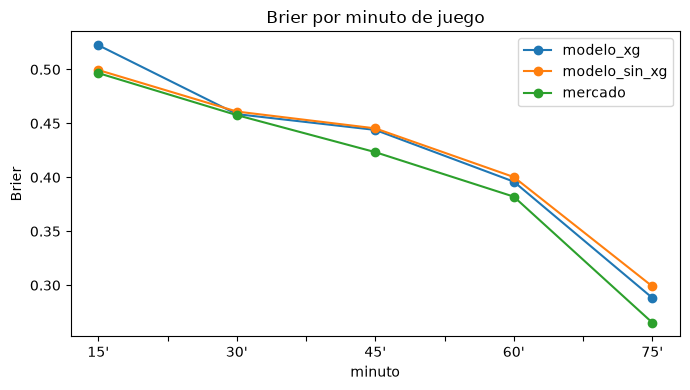

,modelo_xg,modelo_sin_xg,mercado
15',0.522,0.499,0.497
30',0.459,0.461,0.458
45',0.444,0.445,0.423
60',0.396,0.400,0.382
75',0.288,0.299,0.265


In [2]:
brier = pd.DataFrame(resultados["brier"]).T.drop(columns="partidos")
brier.index = [i.replace("min_", "") + "'" for i in brier.index]
ax = brier.plot(marker="o", figsize=(7, 4), title="Brier por minuto de juego")
ax.set_xlabel("minuto"); ax.set_ylabel("Brier")
plt.tight_layout(); plt.savefig(ROOT / "docs" / "backtest_brier_por_minuto.png", dpi=150); plt.show()
brier.round(3)

## 2. Adelanto: ¿la diferencia modelo − mercado anticipa hacia dónde se mueve el precio?

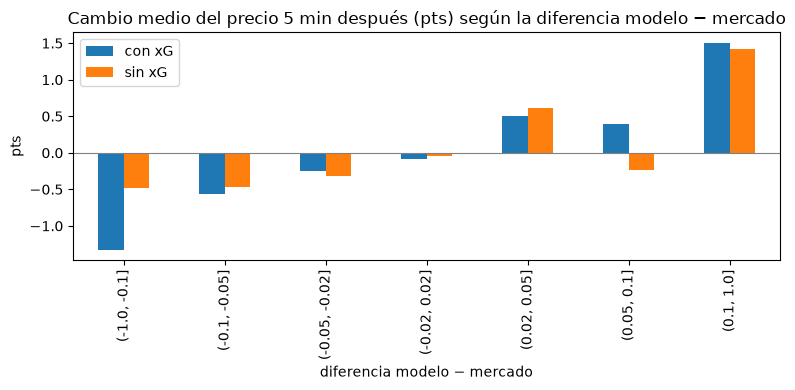

,con_xg,sin_xg
5min,0.038,0.016
10min,0.038,0.013


In [3]:
filas = pd.DataFrame([f for p in por_partido for f in p])
filas["d_xg"] = filas["p_xg"] - filas["mercado"]
filas["d_sin"] = filas["p_sin"] - filas["mercado"]
filas["cambio_5"] = filas["futuro_5"] - filas["mercado"]
bins = [-1, -0.10, -0.05, -0.02, 0.02, 0.05, 0.10, 1]
tabla = pd.DataFrame({
    "con xG": filas.groupby(pd.cut(filas["d_xg"], bins), observed=True)["cambio_5"].mean(),
    "sin xG": filas.groupby(pd.cut(filas["d_sin"], bins), observed=True)["cambio_5"].mean(),
}) * 100
ax = tabla.plot(kind="bar", figsize=(8, 4), title="Cambio medio del precio 5 min después (pts) según la diferencia modelo − mercado")
ax.axhline(0, color="gray", lw=0.8); ax.set_xlabel("diferencia modelo − mercado"); ax.set_ylabel("pts")
plt.tight_layout(); plt.savefig(ROOT / "docs" / "backtest_adelanto.png", dpi=150); plt.show()
pd.DataFrame({k: {h: v["correlacion"] for h, v in d.items()} for k, d in resultados["adelanto"].items()}).round(3)

## 3. Señales BUENO simuladas ($1 por señal, compra al precio del minuto siguiente + 1 pt)

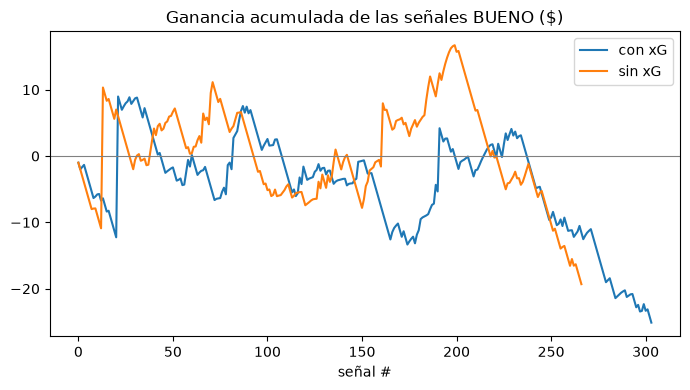

,con_xg,sin_xg
senales,304.000,267.000
aciertos,0.526,0.479
ganancia_por_dolar,-0.083,-0.072
ganancia_total,-25.115,-19.317


In [4]:
def ganancias(columna):
    salida = []
    for p in por_partido:
        previo = {}
        for f in p:
            if f[columna] == "BUENO" and previo.get(f["lado"]) != "BUENO" and f["compra"]:
                salida.append((f["t"], (1 / f["compra"] - 1) if f["gano"] else -1.0))
            previo[f["lado"]] = f[columna]
    return pd.Series([g for _, g in sorted(salida)])

fig, ax = plt.subplots(figsize=(7, 4))
for nombre, col in (("con xG", "senal_xg"), ("sin xG", "senal_sin")):
    ganancias(col).cumsum().reset_index(drop=True).plot(ax=ax, label=nombre)
ax.axhline(0, color="gray", lw=0.8); ax.set_title("Ganancia acumulada de las señales BUENO ($)")
ax.set_xlabel("señal #"); ax.legend(); plt.tight_layout()
plt.savefig(ROOT / "docs" / "backtest_senales.png", dpi=150); plt.show()
pd.DataFrame(resultados["senales"]).round(3)

## 4. Modelo de xG propio (posición del tiro)

ESPN publica la posición de cada tiro. `src/models/xg_modelo.py` entrena una regresión logística sobre distancia
y ángulo a la portería, cabezazo y su interacción con la distancia, con tiros de partidos **anteriores** al periodo
de esta prueba (de hace 22 a 150 días), y la valida con tiros que no usó.

In [5]:
import json
xg_modelo = json.loads((ROOT / "data" / "live" / "modelo" / "xg_modelo.json").read_text(encoding="utf-8"))
display(pd.Series(xg_modelo["entrenamiento"], name="entrenamiento").to_frame())
pd.DataFrame({
    "xG por posición (modelo)": {"AUC": xg_modelo["validacion"]["auc"], "log loss": xg_modelo["validacion"]["log_loss"]},
    "xG por zona del texto": {"AUC": xg_modelo["validacion"]["auc_xg_por_zona"], "log loss": xg_modelo["validacion"]["log_loss_xg_por_zona"]},
    "sin modelo (tasa media)": {"AUC": 0.5, "log loss": xg_modelo["validacion"]["log_loss_base"]},
}).round(3)

,entrenamiento
desde_dias,150
hasta_dias,22
partidos,1004
tiros,28009
goles,2786
penales,253


,xG por posición (modelo),xG por zona del texto,sin modelo (tasa media)
AUC,0.751,0.704,0.500
log loss,0.285,0.301,0.328


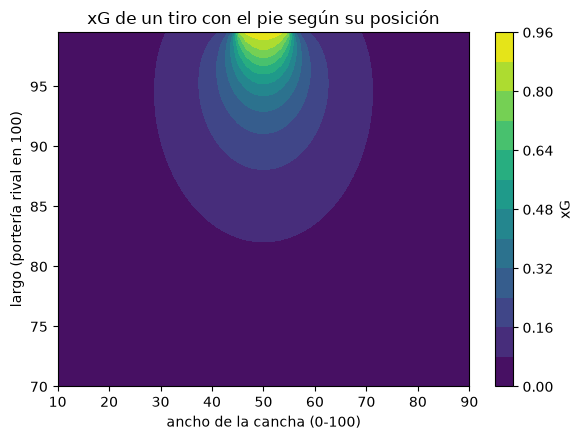

In [6]:
from src.models.xg_modelo import xg_posicion
xs, ys = np.meshgrid(np.linspace(70, 99.5, 60), np.linspace(10, 90, 60))
z = np.vectorize(lambda x, y: xg_posicion(x, y))(xs, ys)
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.contourf(ys, xs, z, levels=12, cmap="viridis")
ax.set_xlabel("ancho de la cancha (0-100)"); ax.set_ylabel("largo (portería rival en 100)")
ax.set_title("xG de un tiro con el pie según su posición"); plt.colorbar(im, label="xG")
plt.tight_layout(); plt.savefig(ROOT / "docs" / "xg_modelo_mapa.png", dpi=150); plt.show()

## 5. Calibración del xG y el momentum (fuera de muestra)

El ritmo de goles mezcla lo esperado antes del partido (pesa como W minutos) con el xG sin penales, y el momentum
(presión reciente) lo ladea con intensidad β. W y β se eligen con los 40 partidos más antiguos; la tabla de abajo
muestra todos los valores probados y el resultado en los 40 más recientes.

In [7]:
cal = resultados["calibracion"]
grilla = pd.DataFrame(cal["grilla"]).pivot(index="peso_previo", columns="peso_momentum", values="brier_ajuste")
display(grilla.round(4).rename_axis(index="W (min)", columns="β momentum"))
pd.DataFrame({"ajuste (40 antiguos)": cal["brier_ajuste"], "prueba (40 recientes)": cal["brier_prueba"]}).round(4)

β momentum,0.0,0.5,1.0,2.0
W (min),,,,
30,0.4193,0.4170,0.4212,0.4472
60,0.4100,0.4080,0.4135,0.4430
120,0.4046,0.4024,0.4085,0.4400
240,0.4021,0.3996,0.4059,0.4382
480,0.4011,0.3984,0.4046,0.4373
960,0.4007,0.3979,0.4041,0.4369


,ajuste (40 antiguos),prueba (40 recientes)
con_xg_momentum,0.3979,0.4466
sin_xg,0.4026,0.4440


## 6. Ruido del mercado: GARCH(1,1) contra varianza constante (QLIKE, menor es mejor)

In [8]:
pd.Series(resultados["garch"]).to_frame("valor")

,valor
qlike_garch,1019.051238
qlike_constante,600.323755
observaciones,8147.000000


## Conclusiones

- **El xG por posición es mucho mejor que el de zona** (AUC 0.75 vs 0.70 en tiros no usados), aunque por debajo
  de los modelos comerciales (~0.78-0.80), que usan datos que ESPN no publica.
- **Con xG y momentum el modelo mejora después del minuto 30** y se adelanta un poco más al mercado (correlación
  0.038 vs 0.016 sin xG). En los 40 partidos no usados para calibrar queda prácticamente igual que sin xG: ya no
  perjudica como el xG por zona. La plataforma predice con xG y momentum con los pesos elegidos (W = 960, β = 0.5).
- **El mercado de Polymarket sigue pronosticando mejor** en todos los minutos, y **las señales BUENO no le ganaron**
  una vez que se simula el atraso real (−8¢ por $1 con xG y momentum; −7¢ sin xG).
- **GARCH no superó a una varianza constante** para el ruido a 5 min; la plataforma usa en la práctica el mínimo
  de 2 pts.
- Limitaciones: 80 partidos de 5 ligas en 21 días; precio de compra estimado como último precio + 1 pt.